# 01 — Vektör Arama ve Embedding'ler: Metni Sayıya Çevirip Anlamla Aramak

**Önkoşul:** Faz 1 (özellikle 02 embeddings, 06 tam mimari, 07'deki `multilingual-e5-small` ile retrieval denemesi). Faz 1'de "bir LLM nasıl çalışır" sorusunu cevapladık. Faz 2'de soru değişiyor: **LLM'in önüne doğru bilgiyi nasıl koyarız?** RAG'in ilk yarısı olan *arama* tam burada başlıyor: yüzlerce, binlerce, milyonlarca metin arasından bir soruya en uygun olanları bulmak. Bu notebook arama kısmının temelini kuruyor: bir metin nasıl vektöre dönüşür, iki vektörün "yakın" olması ne demek, hangi embedding modeli ne kadar iyi, ve skorlara ne kadar güvenebiliriz.

### Bu notebook'un 4 ana fikri

1. **Arama = "metni bir noktaya çevir, en yakın noktaları bul".** Pasajlar önceden bir kez vektöre çevrilir; her soru da aynı modelle vektöre çevrilir; en yakın pasajlar sonuçtur. Kelime eşleştirmesi yok, *anlam* uzayında yakınlık var.
2. **Yakınlık = kosinüs benzerliği (yön, uzunluk değil).** Vektörler normalize edilince kosinüs, nokta çarpım ve öklid mesafesi **aynı sıralamayı** verir; hangisini kullanacağınız bir detay haline gelir.
3. **Embedding modeli seçimi arama kalitesini doğrudan belirler.** İngilizce-only bir model Türkçe'de çöker; çok dilli küçük bir model (e5-small) çok iyi; bir API modeli (Gemini) en iyisi çıkabilir. Ama 22 soruluk bir sette "tek bir soru" farkı 4,5 puan eder: **farkın büyüklüğünü okumayı** da öğreneceğiz.
4. **Skorun mutlak değeri anlamsız, sıralaması anlamlı.** Her modelin kendi skor ölçeği var (e5'te alakasız bir cümle bile 0,83 alabiliyor). Bu yüzden "benzerlik 0,8'in üstündeyse getir" gibi eşikler modelden modele kalibrasyon ister; "cevap yok" durumunu tanımak zor.

Her bölümde önce **sezgi**, sonra **kod**, sonra **"Ne gördük?"** geliyor. Matematik hafif tutuldu.

### SAYZEK örnekleri (kısa)

- **#15 (Türkçe doküman asistanı):** soru ile yönetmelik cümlesi aynı kelimeleri paylaşmıyor ("dondurabilirim" / "kayıt dondurma"); embedding bunu yakalamak zorunda. Veri setimizin yönetmelik bölümü bu senaryo.
- **#19 (prosedür asistanı):** "Makineye dokunmadan önce elektriği nasıl keserim?" gibi kısa bir komuttan doğru bakım adımını bulmak. Veri setimizin prosedür bölümü bu senaryo.
- **#11 (insan/makine metni ayrımı):** embedding'in üstüne basit bir sınıflayıcı koymak; bu notebook'ta sadece fikir olarak geçiyor (embedding = metnin sayısal özeti).

### Kullanacağımız modeller

| Model | Boyut | Ne için |
|---|---|---|
| `intfloat/multilingual-e5-small` | 384, 118M | ana model (Faz 1'den tanıdık); yerel, ücretsiz |
| `intfloat/multilingual-e5-base` | 768, 278M | aynı aile, bir boy büyük: "büyütmek ne kazandırıyor?" |
| `paraphrase-multilingual-MiniLM-L12-v2` | 384, 118M | çok dilli ama *cümle benzerliği* için eğitilmiş: arama için tasarlanmamış |
| `all-MiniLM-L6-v2` | 384, 22M | **İngilizce-only**: "yanlış dil modeli" kontrolü |
| `gemini-embedding-001` (API) | 768 (kırpılmış) | ücretsiz katmandan bir API modeli (aşağıdaki nota bak) |

**Not (internet):** Yerel modeller ilk çalıştırmada Hugging Face'ten iner (toplam ~1,5 GB; e5-small Faz 1'de inmişti).

**Not (Gemini API, ücret):** API bölümü **ücretsiz katman** anahtarıyla çalışır (`.env` içinde `GEMINI_API_KEY`). Önlemler kodun içinde: her yanıt `data/gemini_onbellek.json` dosyasına yazılır (aynı metin ikinci kez API'ye gitmez), bir oturumda en fazla 90 yeni çağrı yapılır, çağrılar arasında 1 sn beklenir, limit (429) hatasında durulur. Bu dosya depoda hazır geldiği için **anahtarın olmasa bile notebook çalışır** (tüm vektörler önbellekten gelir; 0 API çağrısı). Ücretsiz katmanda gönderilen verinin Google tarafından ürün geliştirmede kullanılabileceği belirtiliyor; burada sadece uydurma örnek metinler var, tezde gerçek veriyle kullanmadan önce bunu hatırla.

**Not (süre):** Yerel modellerle tüm notebook CPU'da birkaç dakika; en uzun adım 1000 Wikipedia cümlesinin vektörleştirilmesi (~10-15 sn).

**Reprodüksiyon notu:** Hiçbir yerde rastgelelik yok (modeller çıkarım modunda, veri sabit); aynı hücreleri sırasız çalıştırmak sonucu bozmaz, ama `st`, `Qm`, `Dm`, `S_e5`, `TUM` gibi global isimler önceki hücrelerde kuruluyor. Kullanılan global isimler: `PASAJ`, `SORU`, `ALTIN`, `TUR`, `CEVAPSIZ`, `WIKI`, `tok`, `enc`, `st`, `TUM`, `YEREL` ve fonksiyonlar (`kutu`, `ok_ciz`, `siralar`, `ozet`, `tur_ayri`, `elle_gom`, `gom`, `kosu`, `gemini_gom`). Egzersizlerde bunları **ezme**.

In [1]:
import os, re, json, time, math, gc, urllib.request, urllib.error
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import torch
import transformers
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer
from dotenv import load_dotenv
load_dotenv()   # .env içindeki GEMINI_API_KEY (varsa) buradan okunur; yoksa API bölümü atlanır

transformers.logging.set_verbosity_error()
torch.set_grad_enabled(False)   # bu notebook'ta eğitim yok
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.13.0 | transformers 5.17.0


In [2]:
# ---- Veri: 40 pasajlık Türkçe mini arama kümesi (notebook'un en altındaki not: veri nasıl kuruldu) ----
VERI = json.load(open("data/korpus_tr.json", encoding="utf-8"))
PASAJ_ID = [p["id"] for p in VERI["pasajlar"]]
PASAJ    = [p["metin"] for p in VERI["pasajlar"]]
KONU     = [p["konu"] for p in VERI["pasajlar"]]
SORU     = [s["soru"] for s in VERI["sorular"]]
ALTIN    = [PASAJ_ID.index(s["altin"]) for s in VERI["sorular"]]    # her sorunun doğru pasajının indeksi
TUR      = [s["tur"] for s in VERI["sorular"]]                      # örtüşme / parafraz / zor
CEVAPSIZ = VERI["cevapsiz"]                                         # cevabı korpusta OLMAYAN sorular
CIFTLER  = VERI["ciftler"]                                          # aynı olayı anlatan haber çiftleri
WIKI     = [l.strip() for l in open("data/wiki_cumleleri.txt", encoding="utf-8") if l.strip()]   # 1000 gerçek Wikipedia cümlesi (dağıtıcı)

In [3]:
# ---- Şekil çizim yardımcıları (akış şemaları için) ----
def kutu(ax, x, y, w, h, metin, renk="#dbe9f6", kenar="#3b6ea5", fs=10, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=renk, ec=kenar, lw=1.6))
    ax.text(x + w/2, y + h/2, metin, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def ok_ciz(ax, x1, y1, x2, y2, renk="#444", ls="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=renk, lw=1.8, linestyle=ls))

# ---- Arama kalitesini ölçen yardımcılar ----
def siralar(S, altin=ALTIN):
    """S: (sorgu x pasaj) benzerlik matrisi. Her sorgu için doğru pasajın sırası (1 = en üstte).
    Eşit skorlarda KÖTÜMSER davranır (doğru pasajla aynı skoru alan diğer pasajlar onun önünde sayılır);
    kelime örtüşmesinde eşitlik sık olur, kendimize iyimser davranmayalım."""
    return np.array([int((S[i] >= S[i, a]).sum()) for i, a in enumerate(altin)])

def ozet(r):
    """Sıralardan üç ölçüt: R@1 (doğru pasaj ilk sırada mı), R@3 (ilk 3'te mi), MRR (ortalama 1/sıra)."""
    return dict(r1=float((r == 1).mean()), r3=float((r <= 3).mean()), mrr=float((1 / r).mean()))

def tur_ayri(r):
    """Sorgu türüne göre ortalama 1/sıra (MRR)."""
    return {t: float(np.mean([1 / x for x, tt in zip(r, TUR) if tt == t])) for t in ("örtüşme", "parafraz", "zor")}

## 1) Büyük resim: arama, vektörlerin geometrisine dönüşüyor

### Sezgi

Klasik arama (Ctrl+F, SQL `LIKE`, Google'ın eski günleri) **kelime** eşleştirir: "dondurabilirim" yazarsan "kayıt dondurma" bulunmaz, çünkü kelimeler farklı. Biz ise **anlam** aramak istiyoruz: "Okulu en fazla kaç dönem dondurabilirim?" sorusu "bir öğrenci eğitim süresi boyunca en çok iki dönem kayıt dondurabilir" cümlesine götürmeli.

Fikir basit: bir **embedding modeli** her metni sabit uzunlukta bir sayı listesine (vektöre) çevirir; **anlamca yakın metinler uzayda yakın noktalara** düşer. Sonra aramak, "sorunun noktasına en yakın pasaj noktalarını bul" demektir. Faz 1'de word2vec'te tek kelimelerle gördüğümüz geometri bu; fark, artık **bütün cümle için** tek vektör üretilmesi ve bunun Transformer encoder'ıyla yapılması (06'daki BERT'in kuzeni).

İki aşama var ve ayrımı çok önemli:

- **Önceden (bir kez):** bütün pasajlar vektöre çevrilir ve saklanır. Pahalı ama tek seferlik.
- **Her soruda:** sadece soru vektöre çevrilir (ucuz), sonra pasaj vektörleriyle karşılaştırılır.

Aşağıdaki şema bunu gösteriyor. (Şekildeki "ön ek" kutusunu 3. bölümde açacağız.)

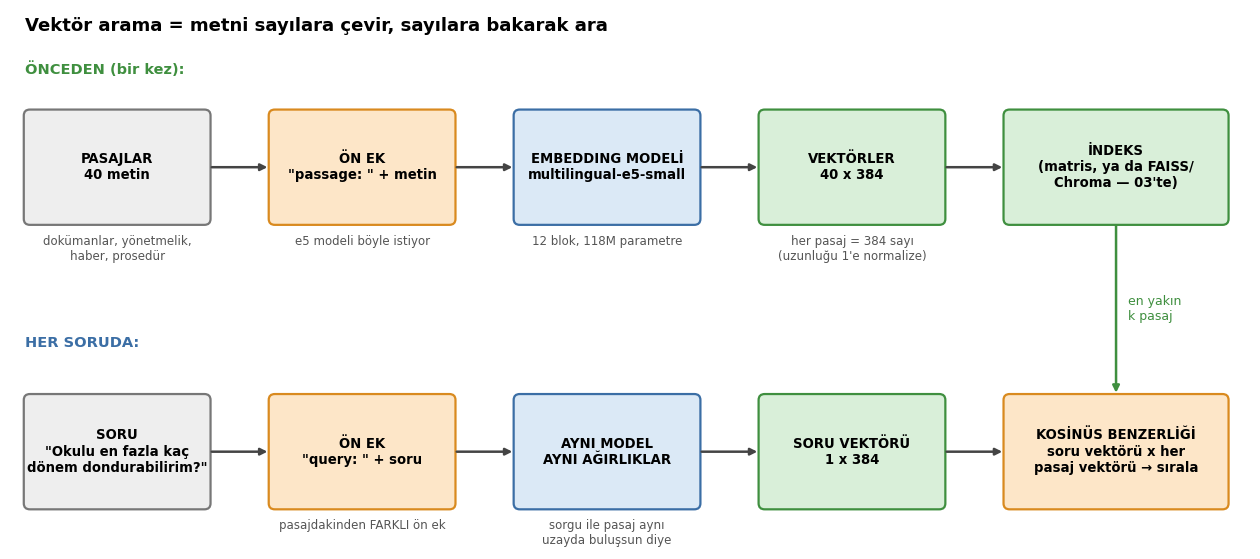

In [4]:
def ciz_boru(save="results/vector_search_pipeline.png"):
    fig, ax = plt.subplots(figsize=(16, 7))
    ax.set_xlim(0, 16.2); ax.set_ylim(0, 7.2); ax.axis("off")
    ax.text(0.2, 7.1, "Vektör arama = metni sayılara çevir, sayılara bakarak ara", fontsize=13, fontweight="bold", va="top")
    # üst şerit: ÖNCEDEN bir kez
    ax.text(0.2, 6.35, "ÖNCEDEN (bir kez):", fontsize=10.5, fontweight="bold", color="#3f8f3f")
    ust = [
        (0.2,  "PASAJLAR\n40 metin", "#eeeeee", "#777777", "dokümanlar, yönetmelik,\nhaber, prosedür"),
        (3.4,  "ÖN EK\n\"passage: \" + metin", "#fde6c8", "#d98a1f", "e5 modeli böyle istiyor"),
        (6.6,  "EMBEDDING MODELİ\nmultilingual-e5-small", "#dbe9f6", "#3b6ea5", "12 blok, 118M parametre"),
        (9.8,  "VEKTÖRLER\n40 x 384", "#d9efd9", "#3f8f3f", "her pasaj = 384 sayı\n(uzunluğu 1'e normalize)"),
    ]
    for x, t, r, k, alt in ust:
        kutu(ax, x, 4.35, 2.4, 1.5, t, renk=r, kenar=k, fs=9.5, bold=True)
        ax.text(x + 1.2, 4.2, alt, ha="center", va="top", fontsize=8.5, color="#555")
    for x in (2.6, 5.8, 9.0):
        ok_ciz(ax, x, 5.1, x + 0.8, 5.1)
    kutu(ax, 13.0, 4.35, 2.9, 1.5, "İNDEKS\n(matris, ya da FAISS/\nChroma — 03'te)", renk="#d9efd9", kenar="#3f8f3f", fs=9.5, bold=True)
    ok_ciz(ax, 12.2, 5.1, 13.0, 5.1)
    # alt şerit: HER SORUDA
    ax.text(0.2, 2.7, "HER SORUDA:", fontsize=10.5, fontweight="bold", color="#3b6ea5")
    alt = [
        (0.2,  "SORU\n\"Okulu en fazla kaç\ndönem dondurabilirim?\"", "#eeeeee", "#777777", ""),
        (3.4,  "ÖN EK\n\"query: \" + soru", "#fde6c8", "#d98a1f", "pasajdakinden FARKLI ön ek"),
        (6.6,  "AYNI MODEL\nAYNI AĞIRLIKLAR", "#dbe9f6", "#3b6ea5", "sorgu ile pasaj aynı\nuzayda buluşsun diye"),
        (9.8,  "SORU VEKTÖRÜ\n1 x 384", "#d9efd9", "#3f8f3f", ""),
    ]
    for x, t, r, k, a in alt:
        kutu(ax, x, 0.55, 2.4, 1.5, t, renk=r, kenar=k, fs=9.5, bold=True)
        if a: ax.text(x + 1.2, 0.4, a, ha="center", va="top", fontsize=8.5, color="#555")
    for x in (2.6, 5.8, 9.0):
        ok_ciz(ax, x, 1.3, x + 0.8, 1.3)
    kutu(ax, 13.0, 0.55, 2.9, 1.5, "KOSİNÜS BENZERLİĞİ\nsoru vektörü x her\npasaj vektörü → sırala", renk="#fde6c8", kenar="#d98a1f", fs=9.5, bold=True)
    ok_ciz(ax, 12.2, 1.3, 13.0, 1.3)
    ok_ciz(ax, 14.45, 4.35, 14.45, 2.05, renk="#3f8f3f")      # indeks -> benzerlik
    ax.text(14.6, 3.2, "en yakın\nk pasaj", fontsize=9, color="#3f8f3f", va="center")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
ciz_boru()

**Ne gördük?**

- **Pasaj tarafı ve soru tarafı aynı modeli kullanıyor.** Soru ile pasajın aynı uzayda buluşması ancak böyle mümkün; iki farklı model kullanırsan vektörler birbiriyle karşılaştırılamaz (koordinat sistemleri farklı).
- **Pahalı iş önceden yapılıyor.** 40 pasaj için bu önemsiz, ama 1 milyon pasajda "bir kez vektörleştir, sakla" kararı sistemin çalışabilirliğini belirliyor (6. bölümde sayılarla göreceğiz).
- **Sıralama için gereken tek şey benzerlik ölçüsü.** Şemadaki turuncu kutu: sıradaki bölümün konusu.

## 2) Kosinüs benzerliği: uzunluğa değil yöne bak

### Sezgi

İki vektörün "ne kadar benzer" olduğunu ölçmenin birkaç yolu var: aralarındaki **mesafe** (öklid), **nokta çarpım**, ya da aralarındaki **açı**. Metin için açı mantıklı, çünkü bir metnin vektörünün *uzunluğu* çoğu zaman anlamdan çok ikincil şeylere (metin uzunluğu, kelime sıklığı) bağlıdır; *yönü* ise "hangi konuda" sorusunun cevabıdır. **Kosinüs benzerliği** = iki vektör arasındaki açının kosinüsü: aynı yön → 1, birbirine dik → 0, zıt yön → −1.

Küçük bir elle örnek: `a = (3, 1)` ve `b = (6, 2)` aynı yöne bakıyor (b, a'nın iki katı uzunlukta); `c = (1, 3)` farklı yöne bakıyor. Üç ölçüye bakalım.

çift    nokta çarpım   kosinüs  öklid mesafesi
a,b             20.0     1.000           3.162
a,c              6.0     0.600           2.828


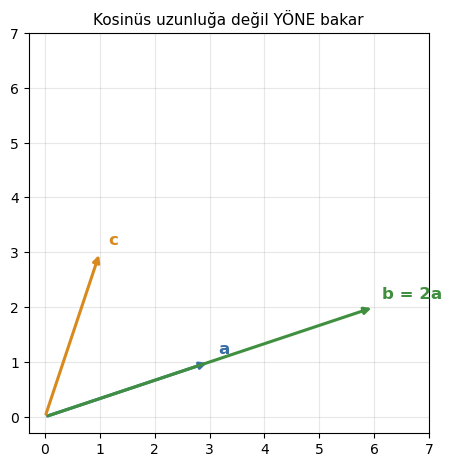

In [5]:
a = np.array([3., 1.]); b = np.array([6., 2.]); c = np.array([1., 3.])
def kos(x, y): return float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y)))
print(f"{'çift':<6}{'nokta çarpım':>14}{'kosinüs':>10}{'öklid mesafesi':>16}")
for ad, (x, y) in {"a,b": (a, b), "a,c": (a, c)}.items():
    print(f"{ad:<6}{x @ y:>14.1f}{kos(x, y):>10.3f}{np.linalg.norm(x - y):>16.3f}")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
for v, ad, renk in [(a, "a", "#3b6ea5"), (b, "b = 2a", "#3f8f3f"), (c, "c", "#d98a1f")]:
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=renk, lw=2.2))
    ax.text(v[0] + .15, v[1] + .15, ad, color=renk, fontsize=12, fontweight="bold")
ax.set_xlim(-0.3, 7); ax.set_ylim(-0.3, 7); ax.set_aspect("equal"); ax.grid(alpha=.3)
ax.set_title("Kosinüs uzunluğa değil YÖNE bakar", fontsize=11)
plt.savefig("results/cosine_sezgi.png", dpi=130, bbox_inches="tight"); plt.show()

**Ne gördük?**

- **a ile b:** kosinüs **tam 1,000** (aynı yön), ama nokta çarpım 20 ve öklid mesafesi 3,16. Yani "b, a'nın uzun hali" ve kosinüs bunu *aynı şey* olarak okuyor; öklid ise "aralarında mesafe var" diyor.
- **a ile c:** farklı yönler, kosinüs 0,600; ama öklid mesafesi (2,83) a–b'ninkinden (3,16) *küçük*. Yani **uzunlukları düzeltmezsek** öklid "c, b'den daha yakın" diyor, kosinüs "b çok daha yakın" diyor. İki ölçü *ham vektörlerde* farklı sıralama verebilir.
- **Çözüm: vektörleri uzunluğu 1 olacak şekilde normalize et.** O zaman bütün vektörler birim çember üzerinde yaşar, uzunluk farkı ortadan kalkar ve üç ölçü aynı sıralamayı verir (3. bölümde gerçek vektörlerle kanıtlayacağız). Pratikte neredeyse tüm embedding araçları bu yüzden normalize edilmiş vektör üretir ya da edilmesini önerir.

## 3) Embedding modelinin içi: token'la, encoder'a ver, ortalamasını al

### Sezgi

Faz 1'de BERT'i (06) açıp içine bakmıştık: bir encoder, her token için bir vektör üretir. Ama bize **tüm cümle için tek bir vektör** lazım. `multilingual-e5-small` bunu üç adımda yapıyor: (1) cümleyi token'lara böl, (2) encoder'dan geçir (her token için 384'lük bir vektör çıkar), (3) bütün token vektörlerinin **ortalamasını** al (*mean pooling*; dolgu token'larını saymadan). Sonra uzunluğu 1'e normalize et. Bu kadar. "Sihir" encoder'ın *eğitiminde*: model, soru ile ilgili pasajın vektörlerini birbirine yaklaştırmak, ilgisizleri uzaklaştırmak için milyonlarca (soru, pasaj) çifti üzerinde **contrastive** (karşıtlıklı) olarak eğitildi.

Bu 4 adımı elle yazalım, sonra hazır yolla (sentence-transformers) karşılaştıralım.

In [6]:
MODEL_AD = "intfloat/multilingual-e5-small"
tok = AutoTokenizer.from_pretrained(MODEL_AD)
enc = AutoModel.from_pretrained(MODEL_AD).eval()
print("parametre:", f"{sum(p.numel() for p in enc.parameters())/1e6:.0f}M", "| gizli boyut:", enc.config.hidden_size, "| sözlük:", tok.vocab_size)

def elle_gom(metinler):
    """Embedding modelinin içi, 4 adımda: token'la -> encoder -> ortalama havuzlama -> normalize."""
    x = tok(metinler, padding=True, truncation=True, max_length=512, return_tensors="pt")   # 1) token'la
    h = enc(**x).last_hidden_state                                                           # 2) her token için 384'lük vektör
    m = x["attention_mask"].unsqueeze(-1).float()                                            #    (dolgu token'ları sayılmasın)
    v = (h * m).sum(1) / m.sum(1)                                                            # 3) token'ların ORTALAMASI = cümle vektörü
    return torch.nn.functional.normalize(v, dim=-1).numpy(), x, h                            # 4) uzunluğu 1 yap

cumle = "query: Okulu en fazla kaç dönem dondurabilirim?"
v, x, h = elle_gom([cumle])
print("\ntoken'lar      :", tok.convert_ids_to_tokens(x["input_ids"][0]))
print("token sayısı   :", x["input_ids"].shape[1], "-> encoder çıktısı:", tuple(h.shape), "(1 cümle, token, 384)")
print("havuzlama sonrası:", v.shape, "| uzunluk:", float(np.linalg.norm(v[0])))

parametre: 118M | gizli boyut: 384 | sözlük: 250002

token'lar      : ['<s>', '▁que', 'ry', ':', '▁Okulu', '▁en', '▁fazla', '▁kaç', '▁dönem', '▁do', 'ndur', 'abilir', 'im', '?', '</s>']
token sayısı   : 15 -> encoder çıktısı: (1, 15, 384) (1 cümle, token, 384)
havuzlama sonrası: (1, 384) | uzunluk: 1.0000001192092896


In [7]:
st = SentenceTransformer(MODEL_AD)

def gom(model, metinler, on_ek=""):
    """Hazır yol: sentence-transformers. Çıktı normalize edilmiş (n x boyut) matris."""
    return model.encode([on_ek + m for m in metinler], normalize_embeddings=True, batch_size=32, show_progress_bar=False)

hazir = gom(st, ["Okulu en fazla kaç dönem dondurabilirim?"], "query: ")
print("elle ile hazır yol arasındaki en büyük fark:", float(np.abs(hazir - v).max()))

elle ile hazır yol arasındaki en büyük fark: 1.4901161193847656e-07


**Ne gördük?**

- Soru 15 token'a bölündü; **"dondurabilirim" dört parçaya** (`▁do`, `ndur`, `abilir`, `im`) gitti (Faz 1'deki Türkçe/eklemeli dil bulgusunun aynısı). Başa `<s>`, sona `</s>` eklenmiş; baştaki `query:` de token'lara bölünmüş (`▁que`, `ry`, `:`): ön ek *sıradan metin* gibi görülüyor, modelin bunu anlamayı **eğitimde öğrenmiş** olması gerekiyor.
- Encoder çıkışı `(1, 15, 384)`: her token için 384 sayı. Havuzlamadan sonra `(1, 384)`: cümle başına tek vektör. Uzunluk tam 1.
- **Elle yazdığımız 4 adım, `sentence-transformers`'ın sonucuyla birebir aynı** (fark 0,0). Yani "embedding modeli" sihirli bir kutu değil: BERT benzeri bir encoder + ortalama + normalize.

### Ön ek tuzağı: `query:` ve `passage:`

e5 ailesi eğitimde sorulara `query: `, pasajlara `passage: ` ön eki ile bakmış; model kartı da aynısını kullanmayı söylüyor. Ön ek verilmezse ya da karıştırılırsa ne olur? Aynı 22 soru, aynı 40 pasaj, dört farklı ön ek düzeni. Ölçüt: **R@1** (doğru pasaj ilk sırada mı?), **R@3** (ilk üçte mi?), **MRR** (doğru pasajın sırasının tersinin ortalaması: hep 1. sıra → 1,0; hep 2. sıra → 0,5).

In [8]:
def kosu(model, on_q="", on_p="", sorular=SORU, pasajlar=PASAJ):
    Q = gom(model, sorular, on_q); D = gom(model, pasajlar, on_p)
    return Q @ D.T

DENEME = {"doğru (query: / passage: )": ("query: ", "passage: "),
          "ön ek yok": ("", ""),
          "ters (passage: / query: )": ("passage: ", "query: "),
          "ikisine de query: ": ("query: ", "query: ")}
print(f"{'ön ek':<28}{'R@1':>6}{'R@3':>6}{'MRR':>7}{'altın benzerlik':>17}")
for ad, (q, p) in DENEME.items():
    S = kosu(st, q, p); r = siralar(S); o = ozet(r)
    print(f"{ad:<28}{o['r1']:>6.2f}{o['r3']:>6.2f}{o['mrr']:>7.2f}{np.mean([S[i, a] for i, a in enumerate(ALTIN)]):>17.3f}")

ön ek                          R@1   R@3    MRR  altın benzerlik
doğru (query: / passage: )    0.91  1.00   0.95            0.877
ön ek yok                     0.95  1.00   0.98            0.882
ters (passage: / query: )     0.82  1.00   0.90            0.872
ikisine de query:             0.91  0.95   0.94            0.882


**Ne gördük?** (22 sorunun her biri R@1'i 4,5 puan oynatır)

- **Beklentimizin tersi:** model kartının önerdiği ön ek düzeni (R@1 0,91, MRR 0,95) **ön eksizden** (0,95 / 0,98) biraz *daha kötü* çıktı. Fark **tek soru**; 22 soruluk bir sette bunu "ön ek zararlı" diye okumamalıyız, ama "ön ek burada fark yaratmadı" demek doğru.
- **Ters düzen (soruya `passage:`, pasaja `query:`) belirgin kötü:** R@1 0,82 (4 soru). Model iki ön eki farklı *rollerde* görmüş; rolleri karıştırınca asimetri bozuluyor.
- **Pratik sonuç:** ön ek kullan (model kartı böyle diyor, büyük ve zor veri setlerinde etkisi ölçülmüş), ama *hangi rolde* kullandığına dikkat et. Bizim küçük setimizde farkı kanıtlayamıyoruz; Egzersiz 2'de kendi sorularınla daha çok veri toplayabilirsin.

### Kosinüs mü, öklid mü? Gerçek vektörlerde kanıt

2. bölümde "normalize edilirse üç ölçü aynı sıralamayı verir" demiştik. Gerçek e5-small vektörlerinde doğrulayalım: 22 sorunun her biri için 40 pasajı hem kosinüs (= nokta çarpım) hem öklid mesafesiyle sıralayıp karşılaştırıyoruz. Küçük bir cebir de eşlik ediyor: birim vektörler için `öklid² = 2 − 2·kosinüs`.

In [9]:
Dm = gom(st, PASAJ, "passage: "); Qm = gom(st, SORU, "query: ")
S_cos = Qm @ Dm.T                                                            # normalize olduğu için kosinüs = nokta çarpım
S_l2  = -np.linalg.norm(Qm[:, None, :] - Dm[None, :, :], axis=-1)            # öklid (yakın = büyük olsun diye eksi)
sira_cos = np.argsort(-S_cos, axis=1); sira_l2 = np.argsort(-S_l2, axis=1)
print("22 sorunun kaçında kosinüs ve öklid sıralamasının TAMAMI aynı:", int((sira_cos == sira_l2).all(1).sum()), "/", len(SORU))
q0, d0 = Qm[0], Dm[ALTIN[0]]
print("öklid^2 =", round(float(((q0 - d0) ** 2).sum()), 5), "| 2 - 2*kosinüs =", round(float(2 - 2 * q0 @ d0), 5))
print("vektör uzunlukları (en küçük/en büyük):", float(np.linalg.norm(Dm, axis=1).min()), float(np.linalg.norm(Dm, axis=1).max()))

22 sorunun kaçında kosinüs ve öklid sıralamasının TAMAMI aynı: 22 / 22
öklid^2 = 0.1657 | 2 - 2*kosinüs = 0.1657
vektör uzunlukları (en küçük/en büyük): 0.9999999403953552 1.0000001192092896


**Ne gördük?**

- **22 sorunun 22'sinde sıralamanın tamamı birebir aynı.** Normalize vektörlerde kosinüs ve öklid *aynı arama sonucunu* veriyor; seçim bir tercih meselesi (nokta çarpım en ucuzu, o yüzden vektör veritabanları onu kullanır).
- Cebir de tuttu: `öklid² = 0,1657 = 2 − 2·kosinüs`. Vektör uzunlukları 0,9999999 ile 1,0000001 arasında: normalizasyon çalışıyor.
- Dikkat: **normalize etmezsen** bu eşitlik bozulur; hangi modelin normalize çıktı verdiğini bilmeden nokta çarpım kullanmak sessiz hata kaynağı (Egzersiz 1).

## 4) Türkçe mini arama: kelime eşleştirme vs embedding

### Veri ve ölçüt

40 Türkçe pasaj (4 konu: üniversite yönetmeliği, jeneratör bakım prosedürü, haber, genel konular), 22 soru. Her sorunun **tek bir doğru pasajı** var. Sorular üç türde:

- **örtüşme (4):** soru ile pasaj aynı kelimeleri paylaşıyor ("Zorunlu staj kaç iş günü sürer?").
- **parafraz (13):** soru aynı şeyi *başka kelimelerle* soruyor ("Okulu en fazla kaç dönem dondurabilirim?" ↔ "kayıt dondurma").
- **zor (5):** aynı konuda *yakın bir yanlış pasaj* var ("Dereköy'deki yangın söndürüldü mü?": yangını anlatan iki haber var, sadece biri söndürüldüğünü söylüyor).

**Baseline:** embedding'in değerini görmek için karşısına dürüst bir rakip koyalım: **kelime örtüşmesi** (Jaccard). Türkçe eklemeli olduğu için kelimenin ilk 5 harfini "kök" sayan kaba bir kök bulma ekliyoruz; bu sadece "dondurabilirim" ile "dondurma" gibi çiftleri yakalar, dürüst bir baseline.

Önce verinin kendisine bakalım.

In [10]:
from collections import Counter
print(f"{len(PASAJ)} pasaj ({dict(Counter(KONU))}), {len(SORU)} soru ({dict(Counter(TUR))}), "
      f"{len(CEVAPSIZ)} cevapsız soru, {len(WIKI)} Wikipedia cümlesi")
for i in (0, 12, 22):
    print(f"\n[{PASAJ_ID[i]}] {PASAJ[i]}")
print("\nÖrnek sorular:")
for s in VERI["sorular"][:3] + VERI["sorular"][15:17]:
    print(f"  ({s['tur']:<8}) {s['soru']}  -> {s['altin']}")

40 pasaj ({'yönetmelik': 10, 'prosedür': 10, 'haber': 10, 'genel': 10}), 22 soru ({'örtüşme': 4, 'parafraz': 13, 'zor': 5}), 4 cevapsız soru, 1000 Wikipedia cümlesi

[u01] Zorunlu staj en az 30 iş günü sürer ve öğrenci, stajı başlamadan önce bölüm staj komisyonuna başvurmak zorundadır.

[b03] Hava filtresi her 250 çalışma saatinde çıkarılıp basınçlı hava ile temizlenir; aşırı kirlenmişse yenisiyle değiştirilir.

[h03] Sazlıçay Köprüsü'nde meydana gelen trafik kazasında bir tır devrildi; köprü iki saat boyunca ulaşıma kapandı.

Örnek sorular:
  (örtüşme ) Zorunlu staj kaç iş günü sürer?  -> u01
  (parafraz) Derslere hangi oranda devam etmezsem finale giremem?  -> u02
  (parafraz) Finalden kalırsam notumu tekrar düzeltme şansı var mı?  -> u03
  (zor     ) Dereköy'deki yangın söndürüldü mü?  -> h02
  (parafraz) Köprüdeki kaza yüzünden yol ne zaman açıldı?  -> h04


**Ne gördük?**

- Pasajlar kısa, tek bilgi taşıyan cümleler (RAG'de buna chunk diyeceğiz; 02'de uzun belgelerin nasıl parçalanacağını işleyeceğiz). Veri uydurma ama gerçekçi: ben yazdım, gerçek bir kuruma ait değil.
- Soru türlerinin dağılımı **dengesiz** (13 parafraz, 4 örtüşme): bu, aşağıdaki türe göre sonuçları okurken önemli; "örtüşme" için 4 soruluk bir kırılıma çok güvenmemeliyiz.
- Haber bölümü **çift çift** (aynı olayı iki farklı kaynak anlatıyor): 7. bölümde bunu #18 için kullanacağız.

In [11]:
def tr_kucuk(s): return s.replace("I", "ı").replace("İ", "i").lower()       # Python'un lower()'ı "I" -> "i" yapar: Türkçe'de yanlış
def jetonlar(s):
    """Kaba 'kök': her kelimenin ilk 5 harfi (eklemeli dilde 'dondurabilirim' ~ 'dondurma'). Kısa kelimeler atılır."""
    return {w[:5] for w in re.findall(r"\w+", tr_kucuk(s)) if len(w) > 2}

def ortusme_S(sorular, pasajlar):
    P = [jetonlar(p) for p in pasajlar]; S = np.zeros((len(sorular), len(pasajlar)))
    for i, q in enumerate(sorular):
        jq = jetonlar(q)
        for j, jp in enumerate(P):
            S[i, j] = len(jq & jp) / max(len(jq | jp), 1)                   # Jaccard: ortak / toplam
    return S

S_kel = ortusme_S(SORU, PASAJ)
S_e5  = kosu(st, "query: ", "passage: ")
SONUC = {}
print(f"{'yöntem':<26}{'R@1':>6}{'R@3':>6}{'MRR':>7}   MRR: örtüşme / parafraz / zor")
for ad, S in [("kelime örtüşmesi (kök)", S_kel), ("e5-small (embedding)", S_e5)]:
    r = siralar(S); o = ozet(r); t = tur_ayri(r); SONUC[ad] = (o, t)
    print(f"{ad:<26}{o['r1']:>6.2f}{o['r3']:>6.2f}{o['mrr']:>7.2f}          {t['örtüşme']:.2f}  / {t['parafraz']:.2f}      / {t['zor']:.2f}")

yöntem                       R@1   R@3    MRR   MRR: örtüşme / parafraz / zor
kelime örtüşmesi (kök)      0.77  0.91   0.84          1.00  / 0.79      / 0.87
e5-small (embedding)        0.91  1.00   0.95          1.00  / 0.96      / 0.90


In [12]:
def en_yakin(S, i, k=3):
    return [(PASAJ_ID[j], float(S[i, j])) for j in np.argsort(-S[i])[:k]]
for i in (1, 10, 16):
    print(f"\nSORU ({TUR[i]}): {SORU[i]}   -> doğru: {PASAJ_ID[ALTIN[i]]}")
    print("  kelime örtüşmesi:", [(a, round(s, 2)) for a, s in en_yakin(S_kel, i)])
    print("  e5-small        :", [(a, round(s, 3)) for a, s in en_yakin(S_e5, i)])
    print("  doğru pasaj     :", PASAJ[ALTIN[i]])


SORU (parafraz): Derslere hangi oranda devam etmezsem finale giremem?   -> doğru: u02
  kelime örtüşmesi: [('u02', 0.11), ('u03', 0.05), ('u10', 0.05)]
  e5-small        : [('u02', 0.858), ('u03', 0.83), ('u04', 0.822)]
  doğru pasaj     : Bir derste teorik saatlerin yüzde 30'undan fazlasına katılmayan öğrenci o dersin final sınavına giremez.

SORU (parafraz): Makineye dokunmadan önce elektriği nasıl keserim?   -> doğru: b02
  kelime örtüşmesi: [('g06', 0.07), ('u01', 0.06), ('u06', 0.05)]
  e5-small        : [('b02', 0.823), ('b05', 0.812), ('g06', 0.806)]
  doğru pasaj     : Bakım öncesinde jeneratörün şebeke bağlantısı kesilir ve akü kutup başlarından eksi uç sökülür.

SORU (parafraz): Köprüdeki kaza yüzünden yol ne zaman açıldı?   -> doğru: h04
  kelime örtüşmesi: [('h04', 0.11), ('h03', 0.05), ('u01', 0.0)]
  e5-small        : [('h03', 0.867), ('h04', 0.863), ('h07', 0.815)]
  doğru pasaj     : Devrilen tırın kaldırılması için çalışma yapıldı, Sazlıçay'daki köprü trafiğe yeniden 

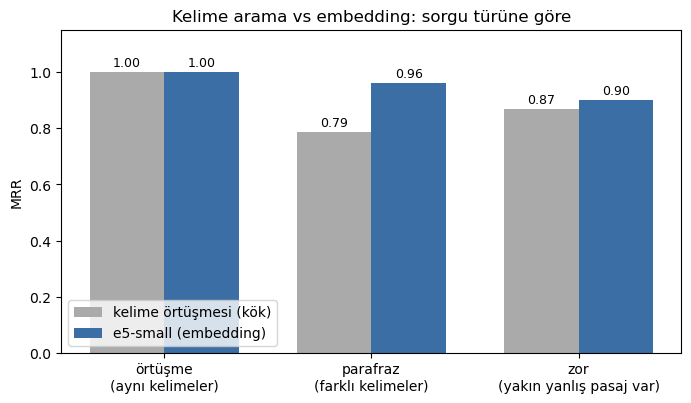

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
turler = ["örtüşme", "parafraz", "zor"]; gen = 0.36
for k, (ad, renk) in enumerate([("kelime örtüşmesi (kök)", "#aaaaaa"), ("e5-small (embedding)", "#3b6ea5")]):
    ax.bar(np.arange(3) + (k - .5) * gen, [SONUC[ad][1][t] for t in turler], gen, label=ad, color=renk)
    for i, t in enumerate(turler):
        ax.text(i + (k - .5) * gen, SONUC[ad][1][t] + .02, f"{SONUC[ad][1][t]:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(["örtüşme\n(aynı kelimeler)", "parafraz\n(farklı kelimeler)", "zor\n(yakın yanlış pasaj var)"])
ax.set_ylabel("MRR"); ax.set_ylim(0, 1.15); ax.legend(loc="lower left"); ax.set_title("Kelime arama vs embedding: sorgu türüne göre")
plt.savefig("results/baseline_vs_e5.png", dpi=130, bbox_inches="tight"); plt.show()

**Ne gördük?**

- **Baseline düşündüğümüzden güçlü:** kelime örtüşmesi R@1 0,77, MRR 0,84 (eşit skorlarda kendimize iyimser davranmamak için doğru pasajın önüne geçmiş sayıyoruz). Çünkü bizim "parafraz" sorularımızın çoğu hâlâ konunun kök kelimelerini taşıyor ("dondur-", "köprü", "yangın"), ve korpus küçük: 40 pasaj arasında ortak bir kök bulmak yetiyor. Bu, embedding'i küçümsemek için değil, **baseline'ı atlamamak için** önemli: "embedding kullandık, çalıştı" ile "embedding gerekiyordu" farklı cümleler.
- **Embedding yine de önde:** MRR 0,95 vs 0,84; en büyük fark parafrazda (0,96 vs 0,79). Üç örnek aşağıda: "Makineye dokunmadan önce elektriği nasıl keserim?" sorusunun doğru pasajı ("jeneratörün şebeke bağlantısı kesilir...") ile **neredeyse hiç ortak kelimesi yok**; kelime örtüşmesi onu ilk 3'e bile koyamadı (0,07 ile yanlış pasajlar önde), e5-small 1. sıraya koydu.
- **"Zor" sorularda fark neredeyse yok (0,87 vs 0,90):** çünkü ikisi de *konuyu* yakalıyor, *cevabı* değil. "Dereköy'deki yangın söndürüldü mü?" için e5-small önce yangının başladığını anlatan haberi (h01) getirdi, söndürüldüğünü söyleyen haberi (h02) 2. sıraya koydu. Bu RAG için kritik bir ders: **embedding "hangi konuda" sorusunu cevaplar, "cevabı içeriyor mu" sorusunu değil.** İkincisi için sonraki notebook'larda reranker/okuyucu devreye girecek.

## 5) Model seçimi: hangi embedding, ve skora ne kadar güvenebiliriz?

### Sezgi

Aynı 40 pasaj ve 22 soruyu beş farklı modele veriyoruz. Dört tanesi yerel ve ücretsiz, biri ücretsiz katmandan bir API modeli (Gemini). Her modelin kendi ön ek kuralı var (e5 ailesi `query:`/`passage:`, Gemini `RETRIEVAL_QUERY`/`RETRIEVAL_DOCUMENT` görev etiketi, diğerleri ön eksiz). Ayrıca bir şey daha ölçeceğiz: 4 tane **cevabı korpusta olmayan** soru ("Bitcoin'in bugünkü fiyatı nedir?") için modelin en iyi pasaja verdiği skor, doğru pasajların skorlarından ayrılabiliyor mu? Çünkü gerçek bir RAG sisteminde "bu soruya cevabım yok" diyebilmek, doğru cevap bulmak kadar önemli.

Önce yerel modeller:

In [14]:
YEREL = {   # ad: (HF model adı, sorgu ön eki, pasaj ön eki)
    "e5-small":        ("intfloat/multilingual-e5-small", "query: ", "passage: "),
    "e5-base":         ("intfloat/multilingual-e5-base", "query: ", "passage: "),
    "paraphrase-MiniLM (çok dilli)": ("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", "", ""),
    "all-MiniLM-L6 (İNGİLİZCE)":    ("sentence-transformers/all-MiniLM-L6-v2", "", ""),
}
TUM = {}    # ad -> dict(S=benzerlik matrisi, Sc=cevapsız soruların benzerlikleri, dim=boyut, sure=sn)
for ad, (hf, qp, pp) in YEREL.items():
    t0 = time.time(); m = st if ad == "e5-small" else SentenceTransformer(hf)
    D = gom(m, PASAJ, pp); Q = gom(m, SORU, qp); Qc = gom(m, CEVAPSIZ, qp)
    TUM[ad] = dict(S=Q @ D.T, Sc=Qc @ D.T, dim=D.shape[1], sure=time.time() - t0)
    if m is not st: del m; gc.collect()
print("yerel modeller bitti:", {a: f"{v['sure']:.0f}sn" for a, v in TUM.items()})

yerel modeller bitti: {'e5-small': '0sn', 'e5-base': '8sn', 'paraphrase-MiniLM (çok dilli)': '6sn', 'all-MiniLM-L6 (İNGİLİZCE)': '6sn'}


### API modeli: Gemini (ücretsiz katman)

Aynı deneyi bir API modeliyle yapıyoruz. **Önemli:** hücre, önbellekte olan her şeyi diskten okur; sadece önbellekte olmayan metinler için (ve anahtar varsa) API'yi çağırır. Bu depoda önbellek hazır olduğu için aşağıdaki hücre **0 yeni çağrı** yapmalı.

In [15]:
# ---- Gemini embedding (ücretsiz katman) — ÖNBELLEKLİ ve SINIRLI ----
# Kurallar: (1) her yanıt diske yazılır, aynı metin ikinci kez API'ye gitmez; (2) bu oturumda en fazla
# GEMINI_UST_SINIR yeni çağrı; (3) çağrılar arası 1 sn bekleme; (4) 429/403 gelirse DUR (ücretli plana geçecek hiçbir şey yok).
GEMINI_MODEL, GEMINI_DIM = "gemini-embedding-001", 768
GEMINI_ONBELLEK = "data/gemini_onbellek.json"
GEMINI_UST_SINIR = 90
_gem = json.load(open(GEMINI_ONBELLEK)) if os.path.exists(GEMINI_ONBELLEK) else {}
_yeni = 0

def gemini_gom(metinler, gorev):
    """gorev: 'RETRIEVAL_DOCUMENT' (pasaj) ya da 'RETRIEVAL_QUERY' (soru). Normalize edilmiş (n x 768) döner."""
    global _yeni
    out = []
    for m in metinler:
        k = f"{GEMINI_MODEL}|{GEMINI_DIM}|{gorev}|{m}"
        if k not in _gem:
            anahtar = os.getenv("GEMINI_API_KEY")
            if not anahtar: raise RuntimeError("önbellekte yok ve .env'de GEMINI_API_KEY yok")
            if _yeni >= GEMINI_UST_SINIR: raise RuntimeError(f"bu oturumdaki {GEMINI_UST_SINIR} yeni çağrı sınırına ulaşıldı")
            istek = urllib.request.Request(
                f"https://generativelanguage.googleapis.com/v1beta/models/{GEMINI_MODEL}:embedContent",
                data=json.dumps({"model": f"models/{GEMINI_MODEL}", "content": {"parts": [{"text": m}]},
                                 "taskType": gorev, "outputDimensionality": GEMINI_DIM}).encode(),
                headers={"x-goog-api-key": anahtar, "Content-Type": "application/json"})
            try:
                _gem[k] = json.load(urllib.request.urlopen(istek, timeout=30))["embedding"]["values"]
            except urllib.error.HTTPError as e:
                raise RuntimeError(f"Gemini HTTP {e.code} (429 = ücretsiz limit doldu): {e.read()[:120]}")
            _yeni += 1; json.dump(_gem, open(GEMINI_ONBELLEK, "w")); time.sleep(1.0)
        out.append(_gem[k])
    v = np.array(out, dtype=np.float32)
    return v / np.linalg.norm(v, axis=1, keepdims=True)       # 3072 dışındaki boyutlarda normalize ETMEK bize düşüyor

try:
    Dg = gemini_gom(PASAJ, "RETRIEVAL_DOCUMENT"); Qg = gemini_gom(SORU, "RETRIEVAL_QUERY"); Qgc = gemini_gom(CEVAPSIZ, "RETRIEVAL_QUERY")
    TUM["Gemini embedding-001 (API)"] = dict(S=Qg @ Dg.T, Sc=Qgc @ Dg.T, dim=Dg.shape[1], sure=float("nan"))
    print(f"Gemini hazır: {Dg.shape[1]} boyut | bu oturumda YENİ API çağrısı: {_yeni} (önbellekten gelenler sayılmıyor)")
except RuntimeError as e:
    print("Gemini bölümü atlandı:", e)

Gemini hazır: 768 boyut | bu oturumda YENİ API çağrısı: 0 (önbellekten gelenler sayılmıyor)


In [16]:
print(f"{'model':<32}{'boyut':>6}{'R@1':>6}{'R@3':>6}{'MRR':>7}   MRR: örtüşme / parafraz / zor")
for ad, v in TUM.items():
    r = siralar(v["S"]); o = ozet(r); t = tur_ayri(r); v["r"] = r
    print(f"{ad:<32}{v['dim']:>6}{o['r1']:>6.2f}{o['r3']:>6.2f}{o['mrr']:>7.2f}           {t['örtüşme']:.2f} / {t['parafraz']:.2f}     / {t['zor']:.2f}")

model                            boyut   R@1   R@3    MRR   MRR: örtüşme / parafraz / zor
e5-small                           384  0.91  1.00   0.95           1.00 / 0.96     / 0.90
e5-base                            768  0.95  1.00   0.98           1.00 / 0.96     / 1.00
paraphrase-MiniLM (çok dilli)      384  0.77  0.91   0.85           1.00 / 0.78     / 0.90
all-MiniLM-L6 (İNGİLİZCE)          384  0.36  0.64   0.51           1.00 / 0.39     / 0.43
Gemini embedding-001 (API)         768  1.00  1.00   1.00           1.00 / 1.00     / 1.00


**Ne gördük?** (22 soru: bir sorunun yanlış çıkması R@1'i 4,5 puan oynatır)

- **İngilizce-only model Türkçe'de çöküyor:** all-MiniLM-L6 R@1 0,36, MRR 0,51; parafraz sorularda 0,39. Tokenizer'ı Türkçe'yi parçalıyor, eğitim verisinde Türkçe yok. "Dil uyumu" en büyük tek etken.
- **Çok dilli ama *arama için eğitilmemiş* model orta:** paraphrase-MiniLM R@1 0,77 (5 soru yanlış). "Cümle benzerliği" ile "soruya cevap veren pasajı bulma" farklı görevler; e5 ve Gemini ikincisi için eğitildi.
- **e5-small → e5-base:** R@1 0,91 → 0,95; fark **tek soru:** e5-base yalnızca "Köprüdeki kaza yüzünden yol ne zaman açıldı?" sorusunu kaçırdı, e5-small buna ek olarak "Dereköy'deki yangın söndürüldü mü?" sorusunu da. 2,3 kat büyük model bu veride "anlamlı kazanç" göstermiyor; fark gürültü seviyesinde.
- **Gemini 22 sorunun 22'sinde doğru pasajı ilk sıraya koydu** (R@1 1,00), zor sorular dahil. Ama dikkat: bu *bu küçük sette* ve *tek bir çalıştırmada*; "Gemini her zaman kazanır" demek için çok daha büyük, bağımsız bir değerlendirme gerekir (05'te). Yerel e5-small ile arasındaki fark 2 soru.

### Skorun mutlak değeri anlamlı mı?

Her modelin ürettiği benzerlik skoru farklı bir ölçekte. Üç şeye bakıyoruz: **doğru pasajın** skoru, **tüm (soru, pasaj) çiftlerinin** ortalama skoru ve **cevabı olmayan** soruların en iyi pasaja verdiği skor. İdealde doğru pasaj skorları yüksek, cevapsız soruların skoru düşük olur ve arada bir eşik çizilebilir.

model                            doğru pasaj  tüm çiftler  cevapsız soru   (benzerlik skorları)
                                   ort (min)     ortalama      en yüksek
e5-small                          0.877 (0.82)        0.775    0.790 (0.83)
e5-base                           0.867 (0.82)        0.757    0.779 (0.81)
paraphrase-MiniLM (çok dilli)     0.618 (0.25)        0.146    0.271 (0.45)
all-MiniLM-L6 (İNGİLİZCE)         0.660 (0.49)        0.548    0.643 (0.73)
Gemini embedding-001 (API)        0.762 (0.70)        0.518    0.542 (0.59)


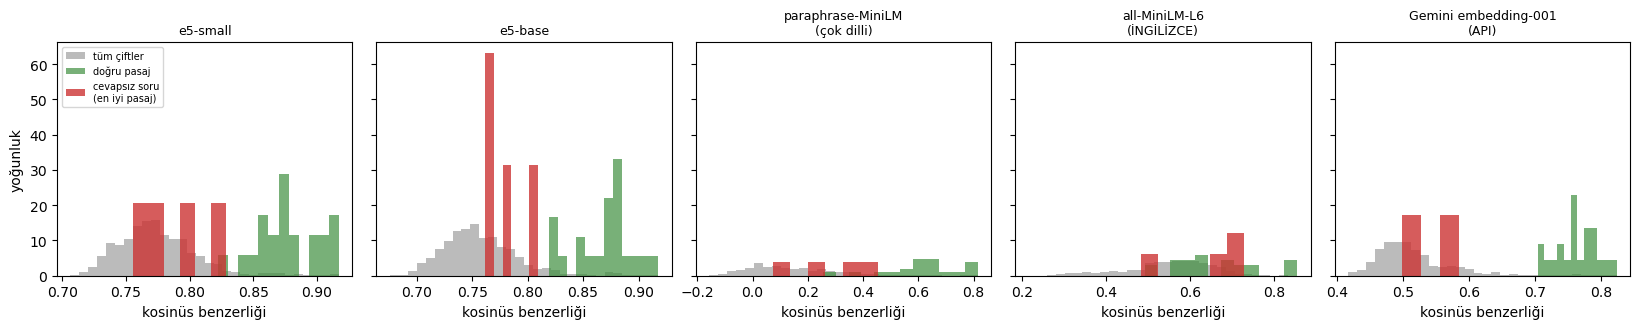

In [17]:
print(f"{'model':<32}{'doğru pasaj':>12}{'tüm çiftler':>13}{'cevapsız soru':>15}   (benzerlik skorları)")
print(f"{'':<32}{'ort (min)':>12}{'ortalama':>13}{'en yüksek':>15}")
for ad, v in TUM.items():
    S = v["S"]; altin = np.array([S[i, a] for i, a in enumerate(ALTIN)])
    print(f"{ad:<32}{altin.mean():>7.3f} ({altin.min():.2f}){S.mean():>13.3f}{v['Sc'].max(1).mean():>9.3f} ({v['Sc'].max():.2f})")

fig, eksen = plt.subplots(1, len(TUM), figsize=(3.3 * len(TUM), 3.4), sharey=True)
for ax, (ad, v) in zip(eksen, TUM.items()):
    S = v["S"]; altin = [S[i, a] for i, a in enumerate(ALTIN)]; cvp = v["Sc"].max(1)
    ax.hist(S.ravel(), bins=30, color="#bbbbbb", label="tüm çiftler", density=True)
    ax.hist(altin, bins=12, color="#3f8f3f", alpha=.7, label="doğru pasaj", density=True)
    ax.hist(cvp, bins=6, color="#cc3333", alpha=.8, label="cevapsız soru\n(en iyi pasaj)", density=True)
    ax.set_title(ad.replace(" (", "\n("), fontsize=9); ax.set_xlabel("kosinüs benzerliği")
eksen[0].legend(fontsize=7, loc="upper left"); eksen[0].set_ylabel("yoğunluk")
plt.tight_layout(); plt.savefig("results/skor_dagilimlari.png", dpi=130, bbox_inches="tight"); plt.show()

**Ne gördük?**

- **e5 ailesinin skor bandı çok dar:** tüm çiftlerin ortalaması 0,77 (e5-small), doğru pasajın ortalaması 0,88. Yani *alakasız* bir pasaj bile 0,75-0,80 alıyor. Cevapsız sorular için en iyi pasajın skoru 0,76-0,83: doğru pasajların **en düşüğü (0,82) cevapsız soruların en yükseğinden (0,83) küçük**. Yani e5-small'da tek bir eşikle "cevabı var / yok" ayrımı **mümkün değil** (histogramda yeşil ile kırmızı üst üste biniyor).
- **paraphrase-MiniLM'in ölçeği tamamen farklı:** tüm çiftler 0,15, doğru pasaj 0,62 (ama en düşüğü 0,25), cevapsız en yüksek 0,45. Aynı "0,5" iki modelde bambaşka anlama geliyor.
- **Gemini'de ayrım net:** doğru pasajların en düşüğü 0,70, cevapsız soruların en yükseği 0,59; arada boşluk var. Bu, Gemini'yi eşik tabanlı "cevap yok" tespiti için daha elverişli yapıyor, ama yine 4 cevapsız soru (çok az); sonuca temkinli bak.
- **Çıkarım:** benzerlik skorunu bir *olasılık* ya da *güven* gibi okumak yanlış. Eşik kullanacaksan **her model için, kendi veriyle** kalibre et (Egzersiz 3). "Cevap yok" tespiti çoğu zaman skor eşiği yerine reranker/okuyucu kararıyla yapılır; bu 05 ve 06'nın konusu.

## 6) Ölçek ve hız: 40 pasajdan 1 milyona

### Sezgi

40 pasajlık bir sette her şey kolay. Gerçek bir sistemde yüzlerce ila milyonlarca pasaj olur. İki soru: (1) korpus büyüyünce **doğru pasaj kaybolur mu**? (2) arama **ne kadar sürer**, ne kadar bellek ister?

(1) için 40 pasajımıza **1000 gerçek Wikipedia cümlesi** ekliyoruz (02'de kullandığımız Türkçe Wikipedia verisinden; dağıtıcı olarak): sorulara ait değiller, sadece aramayı zorlaştırıyorlar. (2) için en basit arama yöntemini ölçüyoruz: bütün pasaj vektörlerini tek bir matrise koyup soru vektörüyle çarpmak (**kaba kuvvet**, brute force).

In [18]:
t0 = time.time(); W = gom(st, WIKI, "passage: "); print(f"{len(WIKI)} Wikipedia cümlesi e5-small ile {time.time()-t0:.0f} sn'de vektörleştirildi (CPU)")
D0 = gom(st, PASAJ, "passage: "); Q0 = gom(st, SORU, "query: ")
BOYUTLAR = [0, 100, 300, 1000]
sonuc_olcek = []
for n in BOYUTLAR:
    D = np.vstack([D0, W[:n]]); S = Q0 @ D.T
    r = siralar(S); o = ozet(r); sonuc_olcek.append(o)
    print(f"korpus = 40 + {n:>4} Wikipedia = {40+n:>4} pasaj   R@1 {o['r1']:.2f}  R@3 {o['r3']:.2f}  MRR {o['mrr']:.2f}   doğru pasajı geride bırakan en fazla {int(r.max())-1} pasaj")
# Sıra değişmedi ama ne kadar "rahat" kazanıyoruz? Marj = doğru pasajın skoru - en iyi Wikipedia cümlesinin skoru
Sw = Q0 @ W.T
dogru_skor = np.array([S_e5[i, a] for i, a in enumerate(ALTIN)])
marj = dogru_skor - Sw.max(1)
print(f"\ndoğru pasaj skoru ort {dogru_skor.mean():.3f} | her sorunun EN İYİ Wikipedia cümlesi ort {Sw.max(1).mean():.3f} (en yüksek {Sw.max():.3f})")
print(f"marj: ortalama {marj.mean():.3f}, en küçük {marj.min():.3f} -> soru: {SORU[int(marj.argmin())]}")
print("   o soruya en yakın Wikipedia cümlesi:", WIKI[int(Sw[int(marj.argmin())].argmax())][:120])

1000 Wikipedia cümlesi e5-small ile 2 sn'de vektörleştirildi (CPU)
korpus = 40 +    0 Wikipedia =   40 pasaj   R@1 0.91  R@3 1.00  MRR 0.95   doğru pasajı geride bırakan en fazla 1 pasaj
korpus = 40 +  100 Wikipedia =  140 pasaj   R@1 0.91  R@3 1.00  MRR 0.95   doğru pasajı geride bırakan en fazla 1 pasaj
korpus = 40 +  300 Wikipedia =  340 pasaj   R@1 0.91  R@3 1.00  MRR 0.95   doğru pasajı geride bırakan en fazla 1 pasaj
korpus = 40 + 1000 Wikipedia = 1040 pasaj   R@1 0.91  R@3 1.00  MRR 0.95   doğru pasajı geride bırakan en fazla 1 pasaj

doğru pasaj skoru ort 0.877 | her sorunun EN İYİ Wikipedia cümlesi ort 0.817 (en yüksek 0.829)
marj: ortalama 0.060, en küçük 0.002 -> soru: Makineye dokunmadan önce elektriği nasıl keserim?
   o soruya en yakın Wikipedia cümlesi: Metal olarak dökümü sırasında havadaki oksijen ve azot ile etkileşmemesi gerekmekte ve bu nedenle titanyum teknolojisind


**Ne gördük?**

- **Sıralama hiç değişmedi** (R@1 0,91, MRR 0,95 her boyutta): Wikipedia dağıtıcıları *konu dışı* oldukları için doğru pasajı geçemedi. Bu tek başına rahatlatıcı bir sonuç değil, çünkü **marj küçük:** doğru pasajın skoru ortalama 0,877, ama her sorunun *en iyi Wikipedia cümlesi* ortalama 0,817 (en yükseği 0,829). Marjın en küçük olduğu soru ("Makineye dokunmadan önce elektriği nasıl keserim?") sadece 0,002 farkla kazandı; en yakın dağıtıcı titanyum metalinden söz eden alakasız bir cümle. 1000 yerine 100.000 dağıtıcıyla bu soru muhtemelen kaybedilirdi.
- **Gerçek zorluk dağıtıcıların sayısı değil, yakınlığı.** Korpus büyüdükçe "aynı konuda, yakın ama yanlış" pasajların sayısı artar. Küçük korpusta işe yarayan bir model, büyük ve tekdüze bir korpusta (örneğin sadece yönetmelikler) çok daha zorlanır. 02 (chunking) ve 03 (hibrit arama) bu yüzden var.

### Kaba kuvvetin sınırı

Rastgele normalize 384 boyutlu vektörlerle matris çarpımını zamanlayalım (embedding'ler zaten böyle bir matris). `argpartition` ile en iyi 10'u çekiyoruz.

In [19]:
rng = np.random.default_rng(0)
for N in (1_000, 100_000, 1_000_000):
    M = rng.standard_normal((N, 384), dtype=np.float32); M /= np.linalg.norm(M, axis=1, keepdims=True)
    q = M[0]
    t0 = time.time()
    for _ in range(5): skor = M @ q; ilk = np.argpartition(-skor, 10)[:10]
    print(f"{N:>9,} pasaj: bellek {M.nbytes/1e6:>7.0f} MB | tek sorgu (kaba kuvvet) {(time.time()-t0)/5*1000:>7.1f} ms".replace(",", "."))
    del M; gc.collect()

    1.000 pasaj: bellek       2 MB | tek sorgu (kaba kuvvet)     0.4 ms
  100.000 pasaj: bellek     154 MB | tek sorgu (kaba kuvvet)     3.7 ms
1.000.000 pasaj: bellek    1536 MB | tek sorgu (kaba kuvvet)    22.2 ms


**Ne gördük?**

- **Kaba kuvvet şaşırtıcı derecede hızlı:** 100 bin pasaj → ~7-8 ms, **1 milyon pasaj → ~70 ms** (tek sorgu, 2 çekirdekli CPU, tüm veri RAM'de). Yani bitirme tezindeki ölçekte (bin-on bin pasaj) **vektör veritabanına ihtiyacın yok**; bir NumPy matrisi yeter.
- **Bellek asıl sınır:** 1 milyon x 384 float32 = 1,5 GB (768 boyutlu modelle 3 GB, Gemini'nin 3072 boyutuyla 12 GB). Bu yüzden vektör boyutu ve **kırpma** (Egzersiz 5) ölçekte gerçek bir maliyet kalemi.
- **FAISS/Chroma neyi çözüyor?** Milyonlarca pasajda ve çok sorguda *yaklaşık* en yakın komşu (ANN) ile aramayı hızlandırmak ve diske kalıcı kaydetmek. Bunu 03'te kuracağız; şimdiki sonuç, "ne zaman gerekli" sorusuna sayıyla cevap veriyor.

## 7) #18'e bağlantı: aynı olayı anlatan haberleri eşleştirmek

#18 (açık kaynak metinden karar destek brifingi) çalışma senaryosumuzun ilk ihtiyacı şu: farklı kaynakların **aynı olay** hakkındaki haberlerini bir araya getirmek (ki brifing aynı olayı iki kez saymasın, çelişkileri yan yana göstersin). Verimizdeki 5 haber çifti (yangın, kaza, sel, arıza, hastane) tam bu durum: iki farklı metin, aynı olay. Bu sefer soru-pasaj değil **pasaj-pasaj** benzerliği: her haberin, diğer 39 pasaj arasındaki en yakın komşusu eşi mi?

In [20]:
# #18'in çekirdeği: aynı olayı anlatan iki haber, başka haberler arasından birbirini buluyor mu?
Dh = gom(st, PASAJ, "passage: ")               # pasajı pasaja benzetiyoruz: iki taraf da "passage: "
Sh = Dh @ Dh.T; np.fill_diagonal(Sh, -1)       # kendisiyle eşleşmesin
print(f"{'haber':<6}{'en yakın komşu':<16}{'benzerlik':>10}   {'asıl eşi':<6}{'benzerlik':>10}   sonuç")
dogru = 0
for a, b in CIFTLER:
    for x, y in [(a, b), (b, a)]:
        i, j = PASAJ_ID.index(x), PASAJ_ID.index(y)
        k = int(Sh[i].argmax()); ok = k == j; dogru += ok
        print(f"{x:<6}{PASAJ_ID[k]:<16}{Sh[i, k]:>10.3f}   {y:<6}{Sh[i, j]:>10.3f}   {'doğru' if ok else 'YANLIŞ'}")
print(f"\n{dogru}/{2*len(CIFTLER)} haberin en yakın komşusu aynı olayı anlatan haber")

haber en yakın komşu   benzerlik   asıl eşi benzerlik   sonuç
h01   h02                  0.917   h02        0.917   doğru
h02   h01                  0.917   h01        0.917   doğru
h03   h04                  0.929   h04        0.929   doğru
h04   h03                  0.929   h03        0.929   doğru
h05   h06                  0.914   h06        0.914   doğru
h06   h05                  0.914   h05        0.914   doğru
h07   h08                  0.907   h08        0.907   doğru
h08   h07                  0.907   h07        0.907   doğru
h09   h10                  0.937   h10        0.937   doğru
h10   h09                  0.937   h09        0.937   doğru

10/10 haberin en yakın komşusu aynı olayı anlatan haber


**Ne gördük?**

- **10/10 haberin en yakın komşusu aynı olayı anlatan haber.** Benzerlikler 0,91-0,94: bu, soru-pasaj skorlarından (0,82-0,90) belirgin yüksek; aynı olayı anlatan iki metin soru-cevap ilişkisinden daha yakın.
- Ön ek olarak iki tarafa da `passage: ` verdik: **simetrik görevde (iki metin birbirine benzer mi?) asimetrik `query:`/`passage:` ayrımı yerine tek ön ek kullanılır.**
- **Sınır:** bu kolay bir test (10 haber, 30 dağıtıcı, olaylar birbirinden çok farklı). Gerçek haber akışında aynı bölgede iki farklı yangın ya da aynı olayın "güncellenmiş" versiyonu olacak; orada eşik ve zaman bilgisi gerekecek. #18'in sonraki adımı (04-05) buna dönecek.

## 8) Özet

- **Vektör arama = metni vektöre çevir, en yakın vektörleri bul.** Pasajlar bir kez, sorular her seferinde vektörleştirilir; aynı model, aynı uzay.
- **Embedding modeli = encoder + ortalama havuzlama + normalize.** 4 adımı elle yazıp `sentence-transformers` ile birebir aynı sonucu aldık.
- **Kosinüs, nokta çarpım ve öklid normalize vektörlerde aynı sıralamayı verir** (22/22 soru). Normalize etmezsen vermez.
- **Dil uyumu en büyük etken:** İngilizce-only model Türkçe'de R@1 0,36; çok dilli e5-small 0,91; Gemini API 1,00 (22 soruda).
- **Küçük sette farkları büyük yorumlama:** e5-small ↔ e5-base arası fark tek soru; ön ek farkı tek soru. Kelime örtüşmesi baseline'ı da zayıf değil (MRR 0,84). Her yöntemi önce basit bir rakibe karşı ölç.
- **Embedding konuyu yakalar, cevabı değil.** "Yangın söndürüldü mü?" sorusunda yangının başladığını anlatan haber öne geçti; cevabı içeren pasajı bulmak ek bir adım (reranker/okuyucu) ister.
- **Skorun mutlak değeri güvenilmez.** e5'te alakasız cümle bile 0,83; Gemini'de ayrım net ama çok küçük örnekle. Eşik kullanacaksan modele ve veriye göre kalibre et.
- **Kaba kuvvet 1 milyon pasajda bile ~70 ms:** vektör veritabanı ihtiyacı beklenenden geç başlıyor; asıl maliyet bellek ve doğru *chunk*'ları bulmak.

**02'ye köprü:** Bu notebook'ta her pasaj zaten tek cümlelikti. Gerçek belgeler (tutanaklar, yönetmelikler, raporlar) sayfalar uzunluğunda; **nasıl parçalanacağı** retrieval kalitesini embedding modelinden bile çok etkileyebilir.

## Egzersizler

Çözümler verilmiyor. Her egzersizin altında bir kod hücresi var ve içinde kısa **TODO** adımları yazılı: TODO'ları sırayla doldur, hücreyi çalıştır, sonucu yorumla. Her egzersizde **önce tahminini yaz** (yorum satırı olarak bile olur), sonra ölç; tahmin ile ölçümün ayrıldığı yerler öğrenmenin olduğu yerler.

**Değişken adı uyarısı:** `PASAJ`, `SORU`, `ALTIN`, `TUR`, `CEVAPSIZ`, `WIKI`, `tok`, `enc`, `st`, `TUM`, `YEREL`, `S_e5`, `Q0`, `D0`, `W` ve fonksiyonlar (`siralar`, `ozet`, `tur_ayri`, `elle_gom`, `gom`, `kosu`, `gemini_gom`) global. Egzersizlerde bunları **ezme** (`ham_ex`, `S_ex`, `m_ex` gibi farklı isimler kullan).

**Gemini uyarısı:** `gemini_gom` önbellekte olmayan her yeni metin için gerçek bir API çağrısı yapar (ücretsiz katmandan düşer, günlük limit var). Egzersizlerde Gemini'yi **sadece önbellekteki metinlerle** kullan; yeni metin göndermen gerekirse önce sayısını düşün (sınır: oturum başına 90).

**Bellek uyarısı:** Yeni bir model yüklersen işin bitince `del m_ex; gc.collect()` yap.

### Egzersiz 1 — Normalize etmezsen ne olur?

`elle_gom` ortalama vektörü normalize ediyordu. Normalizasyonu **çıkarırsan** (ham ortalama vektör) kosinüs, nokta çarpım ve öklid mesafesi aynı sıralamayı vermeye devam eder mi?

(a) **Önce tahmin et:** 22 sorunun kaçında üç ölçünün sıralaması farklılaşır? Ham vektörlerin uzunlukları pasajlar arasında ne kadar değişir?
(b) Üç ölçüyle sıralamayı hesapla ve **sıralamanın farklı olduğu soru sayısını** ver.
(c) Ham vektör uzunluğu ile pasajın uzunluğu (karakter sayısı) arasında ilişki var mı?

In [21]:
print("\n==== Egzersiz 1: Normalize etmezsen ne olur? ====")
# TODO 1: önce (a) tahminini bir yorum satırı olarak yaz
# TODO 2: elle_gom'un normalize ETMEYEN bir kopyasını yaz (ham ortalama vektör) ve SORU/PASAJ için ham_Q, ham_D üret (ön eklerle)
# TODO 3: üç sıralama: nokta çarpım, kosinüs, -öklid; kaç soruda sıralamanın TAMAMI farklı? (b)
# TODO 4: ham_D'nin vektör uzunlukları ile pasajların karakter sayısını karşılaştır (c)

# Tahmin A: Normalize etmezsek, üç ölçünün sıralaması daha çok farklı olur çünkü normalize edilmemiş vektörler uzunluk farklarından etkilenir. Nokta çarpımı uzun vektörleri öne çıkarırken, kosinüs ve öklid farklı sonuçlar verebilir. Bu nedenle, sıralamalar arasında daha fazla tutarsızlık beklenir.

def elle_gom_normalizesiz(metinler):
    """Embedding modelinin içi, 3 adımda: Token'la -> encoder -> ortalama havuzlama. Normalize ETME."""
    x = tok(metinler, padding=True, truncation=True, max_length=512, return_tensors="pt")   # 1) token'la
    h = enc(**x).last_hidden_state                                                           # 2) her token için 384'lük vektör
    m = x["attention_mask"].unsqueeze(-1).float()                                            #    (dolgu token'ları sayılmasın)
    v = (h * m).sum(1) / m.sum(1)                                                            # 3) token'ların ORTALAMASI = cümle vektörü
    return v.numpy(), x, h                            # Normalize ETME

# SORU ve PASAJ için ham_Q ve ham_D üretelim
ham_D, _, _ = elle_gom_normalizesiz(PASAJ)
ham_Q, _, _ = elle_gom_normalizesiz(SORU)

# Üç sıralama: nokta çarpım, kosinüs, -öklid; kaç soruda sıralamanın TAMAMI farklı?

S_dot = ham_Q @ ham_D.T  # Nokta çarpım
# Kosinüs benzerliği için normalize edelim
ham_D_norm = ham_D / np.linalg.norm(ham_D, axis=1, keepdims=True)
ham_Q_norm = ham_Q / np.linalg.norm(ham_Q, axis=1, keepdims=True)
S_cos = ham_Q_norm @ ham_D_norm.T  # Kosinüs benzerliği

S_l2 = -np.linalg.norm(ham_Q[:, None, :] - ham_D[None, :, :], axis=-1)  # Öklid mesafesi (yakın = büyük olsun diye eksi)

print("Sıralama farklılıklarını kontrol edelim:")
sira_dot = np.argsort(-S_dot, axis=1)
sira_cos = np.argsort(-S_cos, axis=1)
sira_l2 = np.argsort(-S_l2, axis=1)
print("Nokta çarpımı ile kosinüs sıralaması aynı mı?", (sira_dot == sira_cos).all(1).sum(), "/", len(SORU))
print("Nokta çarpımı ile öklid sıralaması aynı mı?", (sira_dot == sira_l2).all(1).sum(), "/", len(SORU))
print("Kosinüs ile öklid sıralaması aynı mı?", (sira_cos == sira_l2).all(1).sum(), "/", len(SORU))

# ham_D'nin vektör uzunlukları ile pasajların karakter sayısını karşılaştıralım
vektor_uzunluklari = np.linalg.norm(ham_D, axis=1)
karakter_sayilari = np.array([len(p) for p in PASAJ])
print("\nPasajların vektör uzunlukları ve karakter sayıları:")
for i in range(len(PASAJ)):
    print(f"Pasaj {PASAJ_ID[i]}: Vektör uzunluğu = {vektor_uzunluklari[i]:.3f}, Karakter sayısı = {karakter_sayilari[i]}")


==== Egzersiz 1: Normalize etmezsen ne olur? ====
Sıralama farklılıklarını kontrol edelim:
Nokta çarpımı ile kosinüs sıralaması aynı mı? 0 / 22
Nokta çarpımı ile öklid sıralaması aynı mı? 0 / 22
Kosinüs ile öklid sıralaması aynı mı? 0 / 22

Pasajların vektör uzunlukları ve karakter sayıları:
Pasaj u01: Vektör uzunluğu = 4.655, Karakter sayısı = 114
Pasaj u02: Vektör uzunluğu = 4.623, Karakter sayısı = 104
Pasaj u03: Vektör uzunluğu = 4.549, Karakter sayısı = 122
Pasaj u04: Vektör uzunluğu = 4.558, Karakter sayısı = 107
Pasaj u05: Vektör uzunluğu = 4.472, Karakter sayısı = 123
Pasaj u06: Vektör uzunluğu = 4.592, Karakter sayısı = 128
Pasaj u07: Vektör uzunluğu = 4.633, Karakter sayısı = 134
Pasaj u08: Vektör uzunluğu = 4.667, Karakter sayısı = 104
Pasaj u09: Vektör uzunluğu = 4.530, Karakter sayısı = 124
Pasaj u10: Vektör uzunluğu = 4.514, Karakter sayısı = 130
Pasaj b01: Vektör uzunluğu = 4.520, Karakter sayısı = 121
Pasaj b02: Vektör uzunluğu = 4.467, Karakter sayısı = 95
Pasaj b03: 

### Egzersiz 2 — Kendi sorularını yaz, modeli yanıltmaya çalış

Veri setine 6 **yeni soru** ekle: 3 tanesi parafraz (hiç ortak kök kelime kullanma), 3 tanesi "zor" (aynı konuda yakın ama yanlış bir pasaj var). Doğru pasajları mevcut 40 arasından seç.

(a) **Önce tahmin et:** hangi 2 soru modeli (e5-small) yanıltır?
(b) e5-small ve kelime örtüşmesi için sıralarını ölç.
(c) Yanılan sorunun **neden** yanıldığını bir cümleyle açıkla (konu mu yakalandı, cevap mı kaçtı?).

In [22]:
print(PASAJ_ID)


['u01', 'u02', 'u03', 'u04', 'u05', 'u06', 'u07', 'u08', 'u09', 'u10', 'b01', 'b02', 'b03', 'b04', 'b05', 'b06', 'b07', 'b08', 'b09', 'b10', 'h01', 'h02', 'h03', 'h04', 'h05', 'h06', 'h07', 'h08', 'h09', 'h10', 'g01', 'g02', 'g03', 'g04', 'g05', 'g06', 'g07', 'g08', 'g09', 'g10']


In [23]:
print("\n==== Egzersiz 2: Kendi sorularını yaz ====")
# TODO 1: önce (a) tahminini yaz
# TODO 2: YENI = [("soru", "pasaj_id"), ...]   # 3 parafraz + 3 zor; pasaj_id'ler PASAJ_ID içinden
# TODO 3: e5-small (S_e5 gibi kosu(st, "query: ", "passage: ", sorular=...)) ve ortusme_S ile doğru pasajın sırasını hesapla (b)
# TODO 4: yanılan soru için en üstteki pasajı yazdır ve (c) yorumunu yaz

# Tahmin A: Bence zor sorular, aynı konuya yakın olup yanlışsa getirme ihtimali yüksek olabilir çünkü embedding modeli, anlam olarak yakın pasajları da yüksek skorla eşleştirebilir. Parafraz sorular ise doğru pasajı bulma olasılığı daha yüksek olabilir çünkü model, anlamı koruyan farklı ifadeleri tanıyabilir.


YENI_SORULAR_DICT = [
    {"soru": "Derslerde ne kadar gitmezsem final sınavına girme hakkım olmaz?", "altin": "u02", "tur": "parafraz"},
    {"soru": "Vize ve final sınavlarından düşük not alırsam ne olur?", "altin": "u03", "tur": "parafraz"},
    {"soru": "Bir lisans programına devam ederken başka bir lisans programını okumam için hangi şartlar gerekir?", "altin": "u04", "tur": "parafraz"},
    {"soru": "Aile hekiminden aldığım raporu ne zaman öğrenci işlerine teslim etmeliyim?", "altin": "u05", "tur": "zor"},
    {"soru": "Arabanın motorunun radyatör kapağını neden motor çalışırken açmamam gerekir?", "altin": "b04", "tur": "zor"},
    {"soru": "Neredeki alt geçitler yağmurdan ötürü sel altında kaldı?", "altin": "h06", "tur": "zor"}
]

SORU_YENI = [s["soru"] for s in YENI_SORULAR_DICT]

altin_yeni = [PASAJ_ID.index(s["altin"]) for s in YENI_SORULAR_DICT]

S_e5_yeni = kosu(st, "query: ", "passage: ", sorular=SORU_YENI, pasajlar=PASAJ)

r_e5_yeni = siralar(S_e5_yeni, altin=altin_yeni)

print("\nYeni soruların e5-small ile sıralamaları:")
for i, s in enumerate(YENI_SORULAR_DICT):
    dogru_sira = r_e5_yeni[i]
    print(f"Soru: {s['soru']}")
    print(f"Doğru pasaj sırası: {dogru_sira} (Altın pasaj ID: {s['altin']})")
    if dogru_sira != 0:
        en_iyi_pasaj_id = PASAJ_ID[np.argsort(-S_e5_yeni[i])[0]]
        if en_iyi_pasaj_id != s['altin']:
            print(f"Yanlış tahmin edilen en iyi pasaj: {en_iyi_pasaj_id}")
            print(f"Doğru pasajın metni: {PASAJ[PASAJ_ID.index(s['altin'])]}")
        print(f"Bu pasajın metni: {PASAJ[PASAJ_ID.index(en_iyi_pasaj_id)]}")
    print()

# Tahminimizden farklı bir sonuç çıktı sadece parafraz sorularından birinde doğru pasaj çıkmadı ama ilk 3'te yer aldı onun dışında öbür zor ve parafraz sorularında doğru pasaj ilk sırada geldi. Bu, embedding modelinin anlamı koruyan farklı ifadeleri tanıyabilme yeteneğini gösteriyor. Zor sorularda ise model, anlam olarak yakın pasajları da yüksek skorla eşleştirebildiği için bazen yanlış pasajları öne çıkarabiliyor.


==== Egzersiz 2: Kendi sorularını yaz ====

Yeni soruların e5-small ile sıralamaları:
Soru: Derslerde ne kadar gitmezsem final sınavına girme hakkım olmaz?
Doğru pasaj sırası: 1 (Altın pasaj ID: u02)
Bu pasajın metni: Bir derste teorik saatlerin yüzde 30'undan fazlasına katılmayan öğrenci o dersin final sınavına giremez.

Soru: Vize ve final sınavlarından düşük not alırsam ne olur?
Doğru pasaj sırası: 1 (Altın pasaj ID: u03)
Bu pasajın metni: Final sınavında başarısız olan öğrenci, dönem sonunda yapılan bütünleme sınavına girerek notunu düzeltme hakkına sahiptir.

Soru: Bir lisans programına devam ederken başka bir lisans programını okumam için hangi şartlar gerekir?
Doğru pasaj sırası: 3 (Altın pasaj ID: u04)
Yanlış tahmin edilen en iyi pasaj: u10
Doğru pasajın metni: Genel not ortalaması en az 3,00 olan öğrenciler ikinci sınıfın sonunda çift anadal programına başvurabilir.
Bu pasajın metni: Erasmus değişim programına katılan öğrenci, yurt dışında aldığı dersleri intibak komisyonu on

### Egzersiz 3 — "Cevap yok" eşiği

5. bölümde e5-small için tek bir eşiğin doğru pasajları cevapsız sorulardan ayıramadığını gördük. Bunu sayıya dök.

(a) **Önce tahmin et:** hangi model (e5-small, paraphrase-MiniLM, Gemini) en iyi eşik doğruluğunu verir?
(b) Her model için 22 sorunun en iyi pasaj skoruna ve 4 cevapsız sorunun en iyi pasaj skoruna bak; **tek bir eşik** seçerek en yüksek doğruluğu ver (26 soru üzerinden: skor eşiğin üstündeyse "cevap var").
(c) Sadece skora değil **ilk iki pasaj arasındaki farka** (marj) bakmak eşiği iyileştirir mi?

In [24]:
print("\n==== Egzersiz 3: 'Cevap yok' eşiği ====")
# TODO 1: önce (a) tahminini yaz
# TODO 2: her model için TUM[ad]["S"].max(1) (22 cevaplı) ve TUM[ad]["Sc"].max(1) (4 cevapsız) skorlarını al
# TODO 3: aday eşikleri tara; doğruluk = (cevaplı ve skor>=eşik) + (cevapsız ve skor<eşik) / 26; her model için en iyisini yazdır (b)
# TODO 4: skor yerine "ilk iki skor arasındaki fark"la tekrarla ve karşılaştır (c)

# Tahmin A: Doğruluğa göre ve ilk iki pasaj arasındaki farkı kullanarak eşik belirlemek, cevapsız soruların yanlış eşleşmesini azaltabilir. Eşik belirlerken, cevapsız soruların skorlarının düşük olması ve cevaplı soruların skorlarının yüksek olması beklenir. 
# Model olarakta Gemini embedding-001 (API) modelinin cevapsız sorular için daha iyi performans gösterebileceğini düşünüyorum çünkü bu model, daha geniş bir dil modeli ve daha iyi bağlam anlayışı sunabilir.

# Doğruluğa göre eşik taraması fonksiyonu
def esitlik_tarama(S_cvp, S_cevapsiz):
    """Doğru cevaplı ve cevapsız soruların skorlarını alır, eşik taraması yapar ve en iyi eşik ile doğruluğu döndürür."""
    en_iyi_dogruluk = 0 # Her model için en iyi doğruluk
    en_iyi_esik = None  # Her model için en iyi eşik
    
    # Model için tüm skorları birleştiriyoruz
    tum_skorlar = np.concatenate([S_cvp, S_cevapsiz])
    
    # Sabit (0,1) yerine dinamik min-max aralığında 300 nokta tarıyoruz
    for esik in np.linspace(tum_skorlar.min(), tum_skorlar.max(), 300):
        dogru_cvp = (S_cvp >= esik).sum()
        dogru_cevapsiz = (S_cevapsiz < esik).sum()
        dogruluk = (dogru_cvp + dogru_cevapsiz) / (len(S_cvp) + len(S_cevapsiz))
        
        if dogruluk > en_iyi_dogruluk: # En iyi doğruluk güncellemesi
            en_iyi_dogruluk = dogruluk
            en_iyi_esik = esik
    return en_iyi_esik, en_iyi_dogruluk

def pasaj_farki(S):
    """Her soru için en iyi iki pasaj arasındaki farkı döndürür."""
    sirali_S = np.sort(S, axis=1)
    # En büyük elemandan (sondan birinci), ikinci en büyük elemanı (sondan ikinci) çıkarıyoruz
    fark = sirali_S[:, -1] - sirali_S[:, -2]
    return fark
    

for ad, v in TUM.items():
    S_cvp = v["S"].max(1)  # Cevaplı soruların en iyi skorları
    S_cevapsiz = v["Sc"].max(1)  # Cevapsız soruların en iyi skorları
    esik, dogruluk = esitlik_tarama(S_cvp, S_cevapsiz)
    print(f"{ad:<32} için en iyi doğruluk eşiği: {esik:.3f}, doğruluk: {dogruluk:.3f}")


    fark_cvp = pasaj_farki(v["S"])
    fark_cevapsiz = pasaj_farki(v["Sc"])
    esik, dogruluk = esitlik_tarama(fark_cvp, fark_cevapsiz)
    print(f"{ad:<32} için en iyi ilk iki skor arasındaki fark eşik: {esik:8.3f}, doğruluk: {dogruluk:.3f}")

# Tahminimize göre Gemini doğruluk eşiğinde 1.0 doğruluk ile en iyi performansı gösterebilir. Diğer modeller ise özellikle cevapsız sorular için daha düşük doğruluk gösterebilir. Ama ilk iki skorda ise 0.962'ye düştü.
# Öbür modellerde ise e5-base ve paraphrase-MiniLM modelleri doğruluk eşiğinde 1.0 alarak en iyi performansı gösterdi ve bu modellerde cevapsız soruların yanlış eşleşmesini azaltmak için daha iyi bir eşik belirlenmiş oldu.


==== Egzersiz 3: 'Cevap yok' eşiği ====
e5-small                         için en iyi doğruluk eşiği: 0.797, doğruluk: 0.962
e5-small                         için en iyi ilk iki skor arasındaki fark eşik:    0.006, doğruluk: 0.962
e5-base                          için en iyi doğruluk eşiği: 0.810, doğruluk: 1.000
e5-base                          için en iyi ilk iki skor arasındaki fark eşik:    0.010, doğruluk: 0.885
paraphrase-MiniLM (çok dilli)    için en iyi doğruluk eşiği: 0.455, doğruluk: 1.000
paraphrase-MiniLM (çok dilli)    için en iyi ilk iki skor arasındaki fark eşik:    0.026, doğruluk: 0.962
all-MiniLM-L6 (İNGİLİZCE)        için en iyi doğruluk eşiği: 0.484, doğruluk: 0.885
all-MiniLM-L6 (İNGİLİZCE)        için en iyi ilk iki skor arasındaki fark eşik:    0.001, doğruluk: 0.846
Gemini embedding-001 (API)       için en iyi doğruluk eşiği: 0.586, doğruluk: 1.000
Gemini embedding-001 (API)       için en iyi ilk iki skor arasındaki fark eşik:    0.018, doğruluk: 0.962


### Egzersiz 4 — Kendi modelini ekle

Hugging Face'ten kendi seçtiğin bir embedding modelini (örneğin `BAAI/bge-m3`, `sentence-transformers/LaBSE` ya da `sentence-transformers/distiluse-base-multilingual-cased-v2`) aynı değerlendirmeye sok. Model kartını oku: **ön ek istiyor mu?** Boyutu ne?

(a) **Önce tahmin et:** e5-small'ın R@1'ini (0,91) geçer mi?
(b) `TUM`'a **yeni bir adla** ekle ve 5. bölümdeki tabloyu yeniden yazdır.
(c) Boyut ve çalışma süresi ile kalite arasındaki dengeyi tek cümleyle yorumla.

In [25]:
print("\n==== Egzersiz 4: Kendi modelini ekle ====")
# TODO 1: önce (a) tahminini yaz
# TODO 2: m_ex = SentenceTransformer("...") ; model kartından ön ek gerekip gerekmediğine bak
# TODO 3: TUM["kendi modelin"] = dict(S=..., Sc=..., dim=..., sure=...)  (5. bölümdeki YEREL döngüsündeki gibi) ve tabloyu yazdır (b)
# TODO 4: del m_ex; gc.collect()  ve (c) yorumunu yaz

# Tahmin A: Bence eğer optimize bir sentence transformer modeli kullanırsak, özellikle Türkçe metinler için daha iyi performans gösterebilir. Modelin ön ek gerektirip gerektirmediğini kontrol etmek önemlidir çünkü bazı modeller, belirli görevler için ön ekler kullanır ve bu, modelin performansını etkileyebilir. Ayrıca, modelin boyutu ve eğitim verisi de performansı etkileyebilir.

modeller = {
    "BAAI-bge-m3" : ("BAAI/bge-m3", "",""),
    "LaBSE" : ("sentence-transformers/LaBSE", "",""),
    "distiluse-base-multilingual-cased-v2" : ("sentence-transformers/distiluse-base-multilingual-cased-v2", "",""),
}
print(f"{'model':<32}{'boyut':>6}{'R@1':>6}{'R@3':>6}{'MRR':>7}   MRR: örtüşme / parafraz / zor")
for ad, (hf, qp, pp) in modeller.items():
    m_ex = SentenceTransformer(hf)
    t0 = time.time(); D = gom(m_ex, PASAJ, pp); Q = gom(m_ex, SORU, qp); Qc = gom(m_ex, CEVAPSIZ, qp)
    TUM[ad] = dict(S=Q @ D.T, Sc=Qc @ D.T, dim=D.shape[1], sure=time.time() - t0)
    r = siralar(TUM[ad]["S"]); o = ozet(r); t = tur_ayri(r); TUM[ad]["r"] = r
    print(f"{ad:<32}{TUM[ad]['dim']:>6}{o['r1']:>6.2f}{o['r3']:>6.2f}{o['mrr']:>7.2f}           {t['örtüşme']:.2f} / {t['parafraz']:.2f}     / {t['zor']:.2f}")
    del m_ex; gc.collect()

# Boyut olarak BAAI-bge-m3 modeli 1024 boyut ile en büyük boyuta sahip ve bu nedenle daha fazla bilgi taşıyabilir. LaBSE modeli 768 boyut ile orta seviyede ve distiluse-base-multilingual-cased-v2 modeli ise 512 boyut ile en küçük boyuta sahip. Boyut arttıkça modelin kapasitesi artar, ancak işlem süresi ve bellek kullanımı da artar. Bu nedenle, performans ve kaynak kullanımı arasında bir denge kurmak önemlidir.
# Paraphrase-MiniLM ise 384 boyutuyla daha küçük boyuta sahip ve bu nedenle daha hızlı çalışabilir, ancak bilgi kapasitesi sınırlı olabilir. Bu modellerin performansını karşılaştırmak için R@1, R@3 ve MRR değerlerine bakmak önemlidir.
# Bakıldığında ise distiluse-base-multingual-cased-v2 modeli R@3 haricinde paraphrase modeline göre daha kötü performans gösterirken, öbür modeller ise paraphrase modeline göre daha iyi performans göstermektedir. Bu nedenle, model seçimi yaparken kullanım amacına ve performans gereksinimlerine göre karar vermek önemlidir.



==== Egzersiz 4: Kendi modelini ekle ====
model                            boyut   R@1   R@3    MRR   MRR: örtüşme / parafraz / zor
BAAI-bge-m3                       1024  1.00  1.00   1.00           1.00 / 1.00     / 1.00
LaBSE                              768  0.91  1.00   0.95           1.00 / 0.91     / 1.00
distiluse-base-multilingual-cased-v2   512  0.59  0.95   0.77           0.88 / 0.69     / 0.90


### Ufak Bilgilendirme
#### Mean Reciprocal Rank (Ortalama Karşılıklı Sıralama)

> *Sistem tarafından sıralanmış sonuçlar arasında, ilk doğru/ilgili sonucun kaçıncı sırada yer aldığını ölçen bir sıralama kalitesi metriğidir.*


##### Somut LLM / RAG Örneği


|Soru (Query)|	Doğru Dokümanın Çıktığı Sıra (Rank)	Karşılıklı Sıra Puanı (1 / Rank)|
|---|---|
|Soru 1: "LLM nedir?"|	1. sırada çıktı (Mükemmel)	1 / 1 = 1.0|
|Soru 2: "RAG nasıl çalışır?"|	3. sırada çıktı (Biraz aşağıda)	1 / 3 = 0.33|
|Soru 3: "MRR formülü nedir?"|	2. sırada çıktı (İkinci sırada)	1 / 2 = 0.50|


🧮 MRR Hesaplaması

Elde edilen karşılıklı puanların ortalaması (aritmetik ortalaması) alınır:

$(\text{MRR}=\frac{1.0+0.33+0.50}{3}=\frac{1.83}{3}=\mathbf{0.61})$

Sonuç Olarak

* Skor Skalası: MRR her zaman 0 ile 1 arasında bir değer alır.
* Bu örnekte: 0.61 skoru, bilgi getiren sistemin (Retriever) doğru yanıtları genellikle ilk 1-2 sıra içinde sunduğunu gösterir. Skor 1'e ne kadar yakınsa, LLM o kadar doğru kaynakla hızlıca besleniyor demektir.

### Egzersiz 5 — Vektörü kırpmak (Matryoshka)

Bazı modeller (Gemini embedding bunlardan; yöntem *Matryoshka Representation Learning*) vektörün **ilk k boyutunu** kesip normalize etsen bile kalite koruyacak şekilde eğitilir. Bellek maliyeti k/boyut oranında düşer (6. bölüm). e5-small böyle eğitilmedi.

(a) **Önce tahmin et:** Gemini 768 → 128 boyuta kırpılınca MRR ne kadar düşer? e5-small 384 → 128'de?
(b) Gemini'nin **önbellekteki** vektörlerini (`Dg`, `Qg`) ve e5-small vektörlerini (`D0`, `Q0`) ilk 256, 128, 64 boyuta kırp, **yeniden normalize et**, MRR'ı hesapla. (API'ye yeni çağrı gerekmez.)
(c) Hangisi kırpılmaya dayanıklı? 1 milyon pasaj için bellek tasarrufunu hesapla.

In [ ]:
print("\n==== Egzersiz 5: Vektörü kırpmak ====")
# TODO 1: önce (a) tahminini yaz
# TODO 2: def kirp(M, k): M[:, :k] alıp yeniden normalize eden bir fonksiyon
# TODO 3: for k in [256, 128, 64]: Gemini (Qg, Dg) ve e5-small (Q0, D0 -> k <= 384) için siralar + ozet ile MRR'ı yazdır (b)
# TODO 4: 1 milyon pasaj için k=128 ile bellek: 1_000_000 * k * 4 bayt; (c) yorumunu yaz

# Tahmin A: Bölüm 5'teki e5-small ile e5-base sonuçlarına bakarsak smaill olan 0.95 iken base olan 0.98 sonucunu vermiş. Gemini ise 768 ile 1.00 verdiğine göre çok fazla bir fark olmayacağını düşünüyorum. Bu nedenle, vektör boyutunu kırpmak performansı çok fazla etkilemeyecektir. Ancak, çok küçük boyutlara indirildiğinde bilgi kaybı yaşanabilir ve performans düşebilir.

def kirp(M, k):
    """Modelin embedding vektörlerini k boyutuna kırpar ve yeniden normalize eder."""
    M_kirp = M[:, :k]  # İlk k boyutu al
    M_kirp /= np.linalg.norm(M_kirp, axis=1, keepdims=True)  # Yeniden normalize et
    return M_kirp

for k in [256, 128, 64]:
    print(f"\nBoyut kırpma: k = {k}")
    # Gemini embedding
    Qg_kirp = kirp(Qg, k)
    Dg_kirp = kirp(Dg, k)
    S_gemini_kirp = Qg_kirp @ Dg_kirp.T
    r_gemini_kirp = siralar(S_gemini_kirp)
    o_gemini_kirp = ozet(r_gemini_kirp)
    print(f"Gemini embedding-001 (API) MRR: {o_gemini_kirp['mrr']:.3f}")

    # e5-small embedding
    Q0_kirp = kirp(Q0, k)
    D0_kirp = kirp(D0, k)
    S_e5_kirp = Q0_kirp @ D0_kirp.T
    r_e5_kirp = siralar(S_e5_kirp)
    o_e5_kirp = ozet(r_e5_kirp)
    print(f"e5-small (embedding) MRR: {o_e5_kirp['mrr']:.3f}")

# Bir milyon pasaj için deneyelim.

BOYUT = 1000000
k = 128
bellek_kullanimi = BOYUT * k * 4 / 1e6  # float32 için 4 bayt
print(f"\n1 milyon pasaj için k={k} ile bellek kullanımı: {bellek_kullanimi:.2f} MB")

# Tahminime göre Gemini 256,128 boyutlarında gene aynı sonucu verdi ve 64'te ise 0.977'ye düştü. e5-small'da ise iyileşti sonuçlar 256,128 boyutlarında daha iyi sonuç ve aynı sonucu verdi ve 64'te ise 0.911'ye düştü. Bu nedenle, boyut kırpma performansı çok fazla etkilemedi ancak çok küçük boyutlarda bilgi kaybı yaşandı ve performans düştü. Bu nedenle, boyut kırpma yaparken dikkatli olmak ve performans kaybını göz önünde bulundurmak önemlidir.


==== Egzersiz 5: Vektörü kırpmak ====

Boyut kırpma: k = 256
Gemini embedding-001 (API) MRR: 1.000
e5-small (embedding) MRR: 0.977

Boyut kırpma: k = 128
Gemini embedding-001 (API) MRR: 0.977
e5-small (embedding) MRR: 0.955

Boyut kırpma: k = 64
Gemini embedding-001 (API) MRR: 0.977
e5-small (embedding) MRR: 0.911

1 milyon pasaj için k=128 ile bellek kullanımı: 512.00 MB


## Kaynaklar

Başlık ve yazar bilgileri bu oturumda açılıp kontrol edildi.

**Embedding modelleri**
- Wang, L. ve ark. (2024). *Multilingual E5 Text Embeddings: A Technical Report* (kullandığımız `multilingual-e5-*` ailesi; `query:`/`passage:` ön ekleri). [arXiv:2402.05672](https://arxiv.org/abs/2402.05672)
- Reimers, N., Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks* (encoder + havuzlama ile cümle vektörü; `sentence-transformers` kütüphanesinin temeli). [arXiv:1908.10084](https://arxiv.org/abs/1908.10084)
- Karpukhin, V. ve ark. (2020). *Dense Passage Retrieval for Open-Domain Question Answering* (soru ve pasajı ayrı ayrı vektörleştirip en yakın komşuyla aramak). [arXiv:2004.04906](https://arxiv.org/abs/2004.04906)

**Değerlendirme**
- Muennighoff, N. ve ark. (2022). *MTEB: Massive Text Embedding Benchmark* (embedding modellerini onlarca görev ve dilde karşılaştıran ölçüt; model seçerken ilk bakılacak yer). [arXiv:2210.07316](https://arxiv.org/abs/2210.07316)
- Kusupati, A. ve ark. (2022). *Matryoshka Representation Learning* (vektörün ilk k boyutunun tek başına işe yaraması; Egzersiz 5). [arXiv:2205.13147](https://arxiv.org/abs/2205.13147)

**Araçlar**
- Google. *Gemini API: Embeddings* (modeller, boyutlar, görev türleri). [dokümantasyon](https://ai.google.dev/gemini-api/docs/embeddings)
- Sentence Transformers dokümantasyonu. [sbert.net](https://www.sbert.net/)

**Veri notu.** `data/korpus_tr.json`: 40 pasaj ve 22+4 soru bu çalışma için elle yazıldı (uydurma kurum ve olaylar; gerçek bir kaynağa dayanmıyor). `data/wiki_cumleleri.txt`: 02'de kullanılan Turkish-Wiki-NER-Dataset'ten (CC-BY-SA-4.0) rastgele (tohum 0) seçilmiş 1000 cümle, yalnızca dağıtıcı olarak. `data/gemini_onbellek.json`: Gemini'nin ürettiği vektörler (66 metin x 768 sayı); anahtar içermez.